In [61]:
import sqlite3
import pandas as pd
import numpy as np
from datetime import datetime
import plotly.graph_objects as go 
from plotly.subplots import make_subplots

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
pd.set_option("display.max_columns",50)
pd.set_option("display.width",200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [62]:
modelling_data = pd.read_csv("../customer_data/artifacts/customer_profile_data.csv")
modelling_data.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,CustomerDOB,CustGender,CustLocation,Age,LastAccountBalance,FirstAccountBalance,AvgAccounttBalance,FirstTransaction,LastTransaction,TenureDays
0,CUST00001,111,168,"51,269.29",2,4,3,2007-04-30,Male,London,19.40,615.11,"4,716.01","1,255.05",2024-12-13,2026-05-24,638
1,CUST00002,19,196,"154,678.49",4,5,5,1961-08-07,Male,Newcastle,65.10,584.49,"10,949.29","3,258.89",2024-12-19,2026-08-24,632
2,CUST00003,97,149,"58,059.69",2,3,3,2006-09-02,Male,Leeds,20.00,"6,344.00","3,917.39","4,830.30",2025-01-27,2026-06-07,593
3,CUST00004,14,103,"64,212.54",4,3,3,1975-11-21,Male,Birmingham,50.80,821.46,"3,243.81","1,560.26",2025-09-04,2026-08-29,373
4,CUST00005,72,157,"43,112.11",2,4,2,1962-10-31,Female,Liverpool,63.90,"1,554.08","2,230.21","1,288.83",2025-01-08,2026-07-02,612


In [63]:
customer_transaction_data= pd.read_csv("../customer_data/artifacts/customer_profile_data.csv")

In [64]:
customer_transaction_data.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,CustomerDOB,CustGender,CustLocation,Age,LastAccountBalance,FirstAccountBalance,AvgAccounttBalance,FirstTransaction,LastTransaction,TenureDays
0,CUST00001,111,168,"51,269.29",2,4,3,2007-04-30,Male,London,19.40,615.11,"4,716.01","1,255.05",2024-12-13,2026-05-24,638
1,CUST00002,19,196,"154,678.49",4,5,5,1961-08-07,Male,Newcastle,65.10,584.49,"10,949.29","3,258.89",2024-12-19,2026-08-24,632
2,CUST00003,97,149,"58,059.69",2,3,3,2006-09-02,Male,Leeds,20.00,"6,344.00","3,917.39","4,830.30",2025-01-27,2026-06-07,593
3,CUST00004,14,103,"64,212.54",4,3,3,1975-11-21,Male,Birmingham,50.80,821.46,"3,243.81","1,560.26",2025-09-04,2026-08-29,373
4,CUST00005,72,157,"43,112.11",2,4,2,1962-10-31,Female,Liverpool,63.90,"1,554.08","2,230.21","1,288.83",2025-01-08,2026-07-02,612


array([[<Axes: title={'center': 'Recency'}>,
        <Axes: title={'center': 'Frequency'}>,
        <Axes: title={'center': 'Monetary'}>],
       [<Axes: title={'center': 'R_Score'}>,
        <Axes: title={'center': 'F_Score'}>,
        <Axes: title={'center': 'M_Score'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'LastAccountBalance'}>,
        <Axes: title={'center': 'FirstAccountBalance'}>],
       [<Axes: title={'center': 'AvgAccounttBalance'}>,
        <Axes: title={'center': 'TenureDays'}>, <Axes: >]], dtype=object)

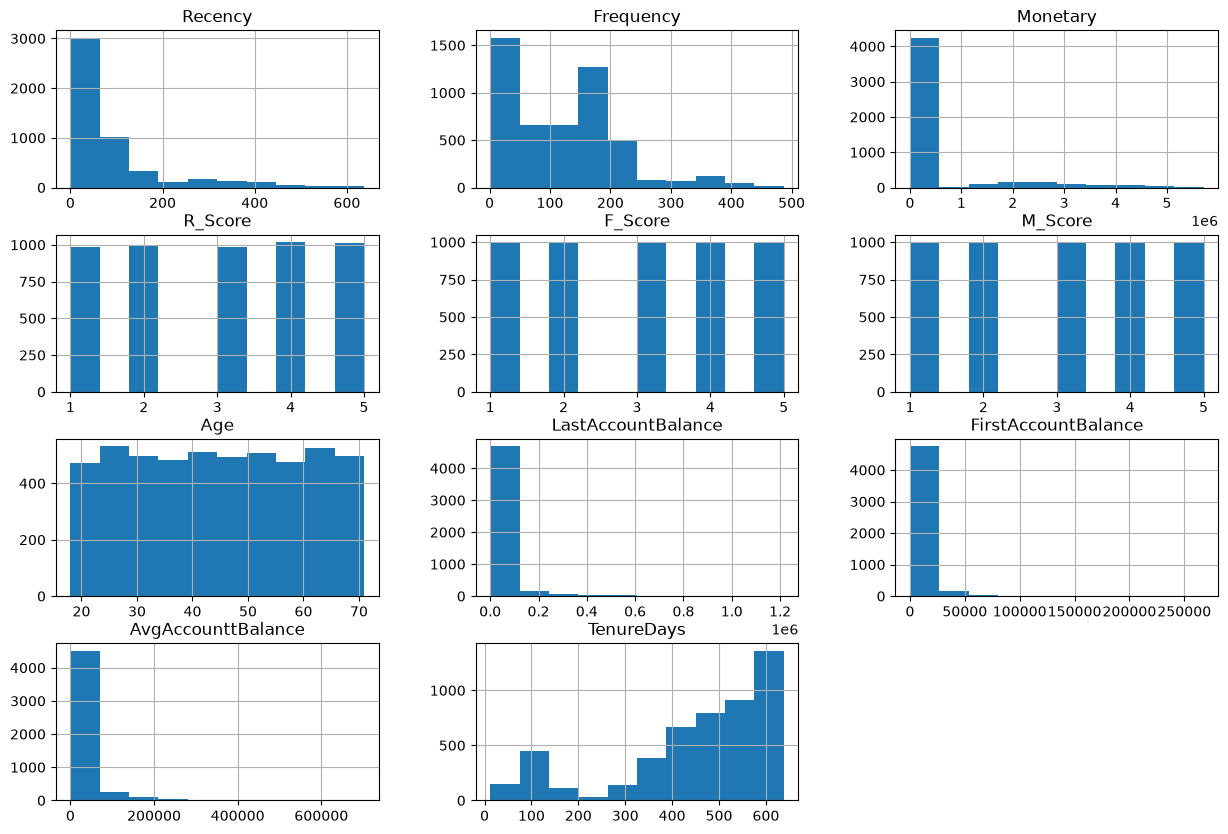

In [65]:
modelling_data.hist(figsize=(15,10))

In [66]:
X = modelling_data[["Recency","Frequency","Monetary"]].copy()

# Log transform the skewed features (Recency stays raw)
X["Recency"] = np.log1p(X["Recency"])
X["Frequency"] = np.log1p(X["Frequency"])
X["Monetary"] = np.log1p(X["Monetary"])

# Standardise so all three features contribute equally

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

array([[<Axes: title={'center': 'Recency'}>,
        <Axes: title={'center': 'Frequency'}>],
       [<Axes: title={'center': 'Monetary'}>, <Axes: >]], dtype=object)

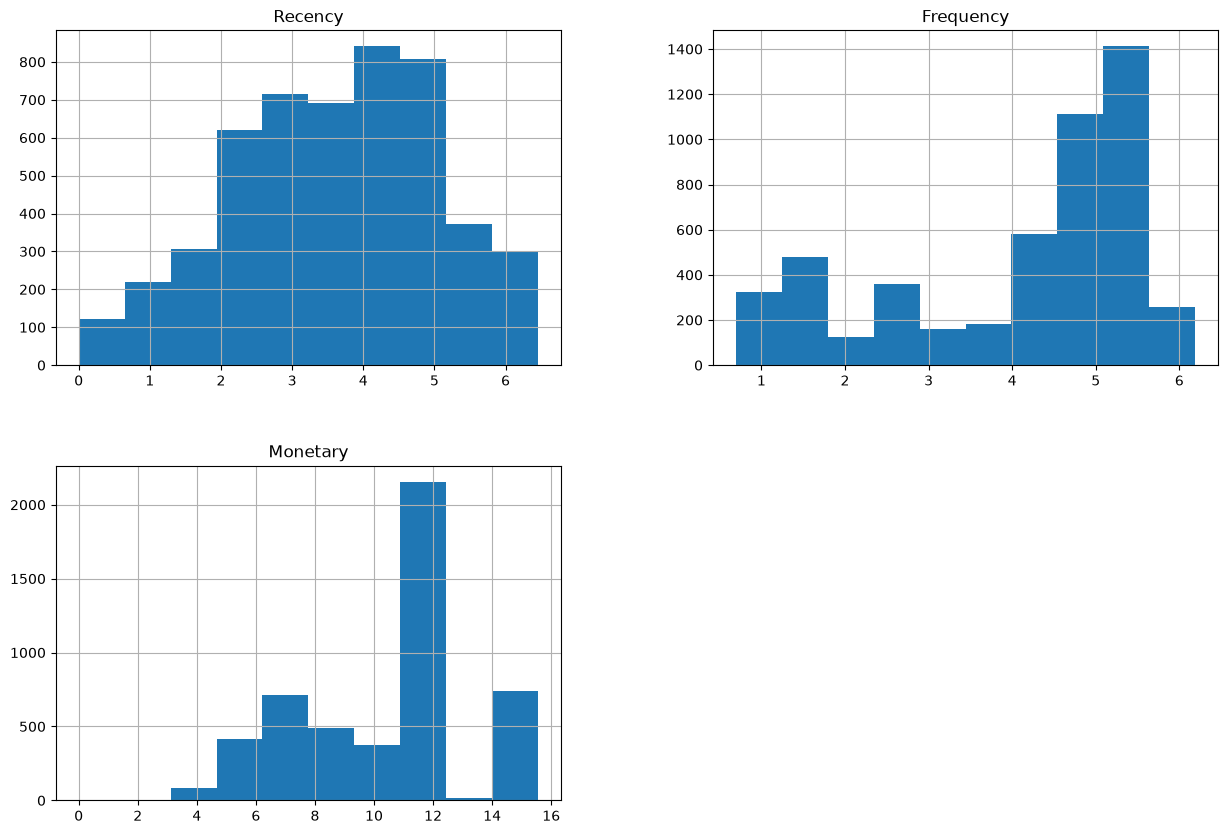

In [67]:
X.hist(figsize=(15,10))

In [68]:
k_range =range(2,11)
inertias = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)


fig = go.Figure()
fig.add_trace(go.Scatter( 
    x=list(k_range), y = inertias,
    mode = "lines+markers",
    marker= dict(size=10),
    line= dict(width=3),
    hovertemplate= "k= %{x},<br>Inertia = %{y:,.0f}<extra></extra>",
))
fig.update_layout(
    title= "Elbow Plot - Inertia vs Number of Clusters",
    xaxis_title= "Number of clusters(k)",
    yaxis_title= "Inertia (within-cluster sum of squares)",
    height= 450,
)
fig.show()


In [69]:
sil_scores = []

for k in k_range: 
    km = KMeans(n_clusters= k, random_state= RANDOM_STATE, n_init= 10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels, sample_size= 5000, random_state=RANDOM_STATE)
    sil_scores.append(score)

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=list(k_range), y= sil_scores,
        mode="lines+markers",
        marker= dict(size=10),
        line=dict(width=3, color="#ff7f0e"),
        hovertemplate= "k = %[x]<br>Silhouette = %{y:4f}<extra></extra>",
    ))
    fig.update_layout(
        title= "Silhouette Score vs Number of Clusters",
        xaxis_title= "Number of clusters(k)",
        yaxis_title= "Average silhouette score",
        height = 450,
    )
fig.show()

#Print the best kby silhouette
best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Best kby silhouette: {best_k}(score= {max(sil_scores):.4f})")









Best kby silhouette: 9(score= 0.5594)


In [70]:
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Elbow - inertia vs k", "Silhouette - separation vs k"),
    horizontal_spacing= 0.15,
)

fig.add_trace(
    go.Scatter(x=list(k_range), y=inertias, mode="lines+markers",
               marker= dict(size=10), line=dict(width=3),
               name="Inertia"),
        row=1,col=1,
               )
fig.add_trace(
    go.Scatter(x=list(k_range), y=sil_scores, mode = "lines+markers",
               marker=dict(size=10), line=dict(width=3, color="#ff7f0e"),
               name= "Silhouette"),
    row=1,col=2,
)

fig.update_xaxes(title_text="k", row=1,col=1)
fig.update_xaxes(title_text="k", row=1,col=2)
fig.update_xaxes(title_text="Inertia", row=1,col=1)
fig.update_xaxes(title_text="Silhouette", row=1,col=2)

fig.update_layout(height = 450, showlegend = False,
                  title_text="K-Means Diagnostics - Choosing k")
fig.show()


In [71]:
CHOSEN_K = 9 # - change basex on the elbow + silhouette

km_final =KMeans(n_clusters=CHOSEN_K, random_state= RANDOM_STATE, n_init= 10)
modelling_data["Cluster"] =km_final.fit_predict(X_scaled)

# Final silhouette for the chosen k
final_sil = silhouette_score(X_scaled,modelling_data["Cluster"],
                             sample_size =5000, random_state=RANDOM_STATE)
print(f"Final model: k = {CHOSEN_K}, silhouette = {final_sil:.4f}")
print(f"Inertia: {km_final.inertia_:,.0f}")

Final model: k = 9, silhouette = 0.5594
Inertia: 921


In [72]:
profile = (modelling_data
           .groupby("Cluster")
           .agg(Customers=("CustomerID","count"),
                Recency=("Recency","mean"),
                Frequency=("Frequency","mean"),
                Monetary= ("Monetary","mean"),
                AvgR= ("R_Score","mean"),
                AvgF= ("F_Score", "mean"),
                AvgM=("M_Score", "mean"))
                .round(2)
                .sort_values("Monetary", ascending=False))

profile["CustomerShare%"] =(100 * profile["Customers"] / profile["Customers"].sum()).round(2)
profile["RevenueShare%"] = (100 * (profile["Monetary"] * profile["Customers"])
                            / (profile["Monetary"] * profile["Customers"]).sum()).round(2)

print(profile.to_string())

         Customers  Recency  Frequency     Monetary  AvgR  AvgF  AvgM  CustomerShare%  RevenueShare%
Cluster                                                                                             
6              272     4.03     349.70 4,046,654.43  4.95  4.93  5.00            5.44          45.61
5              480    70.23      66.22 2,242,046.49  2.44  2.33  5.00            9.61          44.60
4             1294    17.84     166.73   107,760.75  3.97  3.92  3.85           25.90           5.78
0              490     2.97     177.24   103,819.23  5.00  4.13  3.71            9.81           2.11
2              749   113.22     166.23    56,590.26  1.71  3.97  2.68           14.99           1.76
1              283    50.26      54.08     6,583.33  2.90  2.14  2.00            5.66           0.08
7               64     4.31      24.69     2,827.97  4.91  1.73  1.64            1.28           0.01
8              613    51.11      12.78     1,912.15  2.84  1.62  1.62           12.27      

In [73]:
modelling_data.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,CustomerDOB,CustGender,CustLocation,Age,LastAccountBalance,FirstAccountBalance,AvgAccounttBalance,FirstTransaction,LastTransaction,TenureDays,Cluster
0,CUST00001,111,168,"51,269.29",2,4,3,2007-04-30,Male,London,19.40,615.11,"4,716.01","1,255.05",2024-12-13,2026-05-24,638,2
1,CUST00002,19,196,"154,678.49",4,5,5,1961-08-07,Male,Newcastle,65.10,584.49,"10,949.29","3,258.89",2024-12-19,2026-08-24,632,4
2,CUST00003,97,149,"58,059.69",2,3,3,2006-09-02,Male,Leeds,20.00,"6,344.00","3,917.39","4,830.30",2025-01-27,2026-06-07,593,2
3,CUST00004,14,103,"64,212.54",4,3,3,1975-11-21,Male,Birmingham,50.80,821.46,"3,243.81","1,560.26",2025-09-04,2026-08-29,373,4
4,CUST00005,72,157,"43,112.11",2,4,2,1962-10-31,Female,Liverpool,63.90,"1,554.08","2,230.21","1,288.83",2025-01-08,2026-07-02,612,2


In [79]:
import numpy as np
import pandas as pd

profile = modelling_data.groupby("Cluster").agg(Customers=("CustomerID", "count"),
                                                Recency=("Recency","mean"),
                                                Frequency = ("Frequency", "mean"),
                                                Monetary = ("Monetary","mean")).reset_index()

def name_cluster(row):
    r = row["Recency"]
    f = row["Frequency"]
    m = row["Monetary"]

    if r <= 15 and f >= 300 and m >= 1_000_000:
        return "Champions"
    elif m >= 1_000_000 and r > 15:
        return "High-Value At Risk"
    elif r <= 10 and f >= 150:
        return "Active Loyal"
    elif r <= 30 and f >= 150:
        return "Loyal Customer"
    elif r > 180 and f < 20:
        return "Dormant / Lost"
    elif r > 60 and f >= 100:
        return "At Risk"
    elif r <= 30 and f < 100:
        return "Emerging Customers"
    elif f < 20 and m< 5_000:
        return "Low-Value Customers"
    elif r <= 180:
        return "Occasional Customers"
    else:
        return "Dormal / Lost"

profile["SegmentName"] = profile.apply(name_cluster, axis=1)

cluster_to_name = dict(zip(profile["Cluster"],profile["SegmentName"]))

modelling_data["Segment"] = modelling_data["Cluster"].map(cluster_to_name)

print(profile[["Cluster", "Customers", "Recency", "Frequency", "Monetary", "SegmentName"]].round(2).sort_values("Cluster").to_string(index=False))

 Cluster  Customers  Recency  Frequency     Monetary          SegmentName
       0        490     2.97     177.24   103,819.23         Active Loyal
       1        283    50.26      54.08     6,583.33 Occasional Customers
       2        749   113.22     166.23    56,590.26              At Risk
       3        752   314.48       2.97       480.54       Dormant / Lost
       4       1294    17.84     166.73   107,760.75       Loyal Customer
       5        480    70.23      66.22 2,242,046.49   High-Value At Risk
       6        272     4.03     349.70 4,046,654.43            Champions
       7         64     4.31      24.69     2,827.97   Emerging Customers
       8        613    51.11      12.78     1,912.15  Low-Value Customers


In [77]:
profile["SegmentName"].head(18)

0            Active Loyal
1    Occasional Customers
2                 At Risk
3          Dormant / Lost
4          Loyal Customer
5      High-Value At Risk
6               Champions
7      Emerging Customers
8     Low-Value Customers
Name: SegmentName, dtype: str

In [82]:
segment_summary = (modelling_data
                   .groupby("Segment")
                   .agg(Customers=("CustomerID","count"),
                        Recency=("Recency","mean"),
                        Frequency=("Frequency","mean"),
                        Monetary=("Monetary","mean"))
                        .round(2)
                        .sort_values("Monetary", ascending=False))

segment_summary["CustomerShare%"] =(
    100 * segment_summary["Customers"] / segment_summary["Customers"].sum()).round(2)

segment_summary["Revenue"] = (
    modelling_data.groupby("Segment")["Monetary"].sum().round(2))

segment_summary["RevenueShare%"] = (
    100 * segment_summary["Revenue"] / segment_summary["Revenue"].sum()).round(2)

print(segment_summary.to_string())

                      Customers  Recency  Frequency     Monetary  CustomerShare%          Revenue  RevenueShare%
Segment                                                                                                         
Champions                   272     4.03     349.70 4,046,654.43            5.44 1,100,690,005.92          45.61
High-Value At Risk          480    70.23      66.22 2,242,046.49            9.61 1,076,182,314.35          44.60
Loyal Customer             1294    17.84     166.73   107,760.75           25.90   139,442,409.53           5.78
Active Loyal                490     2.97     177.24   103,819.23            9.81    50,871,424.45           2.11
At Risk                     749   113.22     166.23    56,590.26           14.99    42,386,107.96           1.76
Occasional Customers        283    50.26      54.08     6,583.33            5.66     1,863,083.31           0.08
Emerging Customers           64     4.31      24.69     2,827.97            1.28       180,989.9

In [83]:
modelling_data.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,CustomerDOB,CustGender,CustLocation,Age,LastAccountBalance,FirstAccountBalance,AvgAccounttBalance,FirstTransaction,LastTransaction,TenureDays,Cluster,Segment
0,CUST00001,111,168,"51,269.29",2,4,3,2007-04-30,Male,London,19.40,615.11,"4,716.01","1,255.05",2024-12-13,2026-05-24,638,2,At Risk
1,CUST00002,19,196,"154,678.49",4,5,5,1961-08-07,Male,Newcastle,65.10,584.49,"10,949.29","3,258.89",2024-12-19,2026-08-24,632,4,Loyal Customer
2,CUST00003,97,149,"58,059.69",2,3,3,2006-09-02,Male,Leeds,20.00,"6,344.00","3,917.39","4,830.30",2025-01-27,2026-06-07,593,2,At Risk
3,CUST00004,14,103,"64,212.54",4,3,3,1975-11-21,Male,Birmingham,50.80,821.46,"3,243.81","1,560.26",2025-09-04,2026-08-29,373,4,Loyal Customer
4,CUST00005,72,157,"43,112.11",2,4,2,1962-10-31,Female,Liverpool,63.90,"1,554.08","2,230.21","1,288.83",2025-01-08,2026-07-02,612,2,At Risk


In [89]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Data
seg_counts = modelling_data["Segment"].value_counts().reset_index()
seg_counts.columns = ["Segment", "Customers"]

fig = make_subplots(
    rows=1,cols=2,
    specs=[[{"type":"xy"}, {"type":"domain"}]],
    subplot_titles= ("Customer Count per Segment", "Segment Share of Customers"),
    horizontal_spacing= 0.12,
)

# 1a - Bar
fig.add_trace(
    go.Bar(
        x = seg_counts["Segment"], y= seg_counts["Customers"],
        marker_color=px.colors.qualitative.Bold[:len(seg_counts)],
        text = seg_counts["Customers"], textposition="outside",
        showlegend= False,  name = "Customers",
    ),
    row=1,col=1
)

# 1b - Pie (donut)
fig.add_trace(
    go.Pie(
        labels= seg_counts["Segment"], values=seg_counts["Customers"],
        hole = 0.5, textinfo= "label+percent",
        marker=dict(colors=px.colors.qualitative.Bold),
        showlegend= False,
    ),
    row=1,col=2,
)
fig.update_xaxes(tickangle=25, row=1,col=1)
fig.update_layout(height=480, title_text = "Segment Overview")
fig.show()

In [97]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Prepare segment profile data
seg_profile = (
    modelling_data
    .groupby("Segment")
    .agg(
        Recency=("Recency", "mean"),
        Frequency=("Frequency", "mean"),
        Monetary=("Monetary", "mean"),
        Age=("Age", "mean")
    )
    .reset_index()
)

# 2. Calculate total monetary value per segment
rev_by_seg = (
    modelling_data
    .groupby("Segment")["Monetary"]
    .sum()
    .reset_index()
)

# 3. Calculate gender composition per segment
gender_seg = (
    modelling_data
    .groupby(["Segment", "CustGender"])
    .size()
    .reset_index(name="Count")
)

# 4. Create dashboard
fig = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "domain"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Revenue Share per Segment",
        "Average Recency & Frequency",
        "Gender Composition per Segment",
        "Average Age per Segment"
    ),
    horizontal_spacing=0.18,
    vertical_spacing=0.25
)

# --------------------------------------------------
# Revenue Share Donut Chart
# --------------------------------------------------
fig.add_trace(
    go.Pie(
        labels=rev_by_seg["Segment"],
        values=rev_by_seg["Monetary"],
        hole=0.55,
        textinfo="percent",
        textposition="outside",
        marker=dict(colors=px.colors.qualitative.Bold),
        showlegend=False
    ),
    row=1,
    col=1
)

# --------------------------------------------------
# Recency
# --------------------------------------------------
fig.add_trace(
    go.Bar(
        x=seg_profile["Segment"],
        y=seg_profile["Recency"],
        name="Avg Recency",
        marker_color=px.colors.qualitative.Bold[0],
        showlegend=False
    ),
    row=1,
    col=2
)

# --------------------------------------------------
# Frequency
# --------------------------------------------------
fig.add_trace(
    go.Bar(
        x=seg_profile["Segment"],
        y=seg_profile["Frequency"],
        name="Avg Frequency",
        marker_color=px.colors.qualitative.Bold[1],
        showlegend=False
    ),
    row=1,
    col=2
)

# --------------------------------------------------
# Gender Composition
# --------------------------------------------------
for i, gender in enumerate(gender_seg["CustGender"].unique()):

    sub = gender_seg[
        gender_seg["CustGender"] == gender
    ]

    fig.add_trace(
        go.Bar(
            x=sub["Segment"],
            y=sub["Count"],
            name=str(gender),
            marker_color=px.colors.qualitative.Bold[
                i % len(px.colors.qualitative.Bold)
            ]
        ),
        row=2,
        col=1
    )

# --------------------------------------------------
# Average Age
# --------------------------------------------------
fig.add_trace(
    go.Bar(
        x=seg_profile["Segment"],
        y=seg_profile["Age"],
        text=seg_profile["Age"].round(1),
        textposition="outside",
        marker_color=px.colors.qualitative.Bold[2],
        name="Average Age",
        showlegend=False
    ),
    row=2,
    col=2
)

# --------------------------------------------------
# Layout Improvements
# --------------------------------------------------
fig.update_layout(
    title={
        "text": "Segment Behaviour and Demographics",
        "x": 0.5
    },
    width=1400,
    height=1200,
    barmode="group",
    template="plotly_white",
    margin=dict(
        l=50,
        r=50,
        t=120,
        b=100
    ),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.08,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    )
)

# Rotate labels for readability
fig.update_xaxes(
    tickangle=45,
    automargin=True
)

# Add axis titles
fig.update_yaxes(
    title_text="Value",
    row=1,
    col=2
)

fig.update_yaxes(
    title_text="Customer Count",
    row=2,
    col=1
)

fig.update_yaxes(
    title_text="Average Age",
    row=2,
    col=2
)

# Display dashboard
fig.show()

In [98]:
modelling_data.head(20)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,CustomerDOB,CustGender,CustLocation,Age,LastAccountBalance,FirstAccountBalance,AvgAccounttBalance,FirstTransaction,LastTransaction,TenureDays,Cluster,Segment
0,CUST00001,111,168,"51,269.29",2,4,3,2007-04-30,Male,London,19.40,615.11,"4,716.01","1,255.05",2024-12-13,2026-05-24,638,2,At Risk
1,CUST00002,19,196,"154,678.49",4,5,5,1961-08-07,Male,Newcastle,65.10,584.49,"10,949.29","3,258.89",2024-12-19,2026-08-24,632,4,Loyal Customer
2,CUST00003,97,149,"58,059.69",2,3,3,2006-09-02,Male,Leeds,20.00,"6,344.00","3,917.39","4,830.30",2025-01-27,2026-06-07,593,2,At Risk
3,CUST00004,14,103,"64,212.54",4,3,3,1975-11-21,Male,Birmingham,50.80,821.46,"3,243.81","1,560.26",2025-09-04,2026-08-29,373,4,Loyal Customer
4,CUST00005,72,157,"43,112.11",2,4,2,1962-10-31,Female,Liverpool,63.90,"1,554.08","2,230.21","1,288.83",2025-01-08,2026-07-02,612,2,At Risk
5,CUST00006,9,158,"118,339.15",5,4,4,1971-05-07,Male,London,55.40,714.62,"13,899.09","4,431.66",2025-03-28,2026-09-03,533,4,Loyal Customer
6,CUST00007,332,3,257.40,1,1,1,1997-09-27,Female,Birmingham,29.00,"2,976.41","3,200.44","3,111.65",2024-12-22,2025-10-15,629,3,Dormant / Lost
7,CUST00008,18,103,"103,981.40",4,3,4,1995-04-01,Male,Reading,31.40,"2,428.71","13,177.96","12,476.41",2025-07-03,2026-08-25,436,4,Loyal Customer
8,CUST00009,6,191,"91,580.74",5,5,4,2002-03-19,Female,Southampton,24.50,29.36,195.24,"4,222.79",2025-08-13,2026-09-06,395,0,Active Loyal
9,CUST00010,77,160,"50,161.48",2,4,2,1957-09-07,Female,Belfast,69.00,495.06,"3,606.73","1,370.73",2025-03-11,2026-06-27,550,2,At Risk


2. Account Balance Changes by Customer Segment
- FirstAccountBalance: The customer's account balance recorded at their first transaction.
- LastAccountBalance: The customer's account balance recorded at their last transaction.
- Balance Change: LastAccountBalance minus FirstAccountBalance.
- Median: The middle value of the balance changes within each segment.
- Purpose: To compare balance increases and decreases across customer segments and identify patterns that may need further investigation.

In [99]:

import plotly.express as px

balance_data = modelling_data.copy()

# Calculate account balance changes
balance_data["BalanceChange"] = (
    balance_data["LastAccountBalance"]
    - balance_data["FirstAccountBalance"]
)

# Calculate median balance change per segment
balance_profile = (
    balance_data
    .groupby("Segment", as_index=False)
    .agg(MedianBalanceChange=("BalanceChange", "median"))
    .sort_values("MedianBalanceChange", ascending=False)
)

# Classify balance changes
balance_profile["Direction"] = balance_profile[
    "MedianBalanceChange"
].apply(lambda x: "Increase" if x >= 0 else "Decrease")

fig = px.bar(
    balance_profile,
    x="Segment",
    y="MedianBalanceChange",
    color="Direction",
    color_discrete_map={
        "Increase": "#2ca02c",
        "Decrease": "#d62728"
    },
    text="MedianBalanceChange",
    title="Median Account Balance Change by Segment"
)

fig.update_traces(
    texttemplate="%{text:,.0f}",
    textposition="outside"
)

fig.update_layout(
    height=550,
    xaxis_title="Customer Segment",
    yaxis_title="Median Balance Change",
    xaxis_tickangle=35,
    template="plotly_white"
)

fig.add_hline(y=0, line_color="gray")

fig.show()


3. Customer Tenure vs Monetary Value
Markdown cell
 Copy
3. Customer Tenure vs Monetary Value
- TenureDays: The number of days between a customer's first and last recorded transactions.
- Monetary: The customer's total transaction value used in RFM analysis.
- Scatter Plot: Represents each customer as a point based on tenure and monetary value.
- Log Scale: Helps display customers with very different monetary values on the same chart.
- Purpose: To investigate whether customers with longer transaction histories tend to generate higher monetary value.

In [100]:

import plotly.express as px

# Keep valid values for plotting
tenure_data = modelling_data[
    (modelling_data["Monetary"] > 0)
    & modelling_data["TenureDays"].notna()
].copy()

fig = px.scatter(
    tenure_data,
    x="TenureDays",
    y="Monetary",
    color="Segment",
    hover_data=["CustomerID", "Frequency", "Recency"],
    log_y=True,
    opacity=0.6,
    title="Customer Tenure vs Monetary Value",
    color_discrete_sequence=px.colors.qualitative.Bold
)

fig.update_traces(
    marker=dict(size=7)
)

fig.update_layout(
    height=600,
    xaxis_title="Customer Tenure (Days)",
    yaxis_title="Monetary Value (Log Scale)",
    legend_title="Customer Segment",
    template="plotly_white"
)

fig.show()


4. Geographic Distribution of Customer Segments
- CustLocation: The geographic location associated with each customer.
- Segment: The customer group assigned through K-Means clustering.
- Heatmap: Uses colour intensity to represent the number of customers in each location and segment.
- Top 12 Locations: The twelve locations with the highest customer counts.
- Purpose: To identify geographic concentrations of loyal, high-value and at-risk customers for targeted marketing and retention strategies.

In [101]:

import pandas as pd
import plotly.express as px

# Identify the 12 locations with the most customers
top_locations = (
    modelling_data["CustLocation"]
    .value_counts()
    .head(12)
    .index
)

# Filter the dataset
geo_data = modelling_data[
    modelling_data["CustLocation"].isin(top_locations)
]

# Count customers by location and segment
geo_profile = pd.crosstab(
    geo_data["CustLocation"],
    geo_data["Segment"]
)

# Sort locations by total customer count
geo_profile = geo_profile.loc[
    geo_profile.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

# Create the heatmap
fig = px.imshow(
    geo_profile,
    labels={
        "x": "Customer Segment",
        "y": "Customer Location",
        "color": "Customers"
    },
    color_continuous_scale="Viridis",
    aspect="auto",
    text_auto=True,
    title="Geographic Distribution of Customer Segments"
)

fig.update_layout(
    height=650,
    xaxis_tickangle=35,
    template="plotly_white"
)

fig.show()


5. RFM Score Comparison Across Customer Segments
- R_Score (Recency): A score from 1–5 showing how recently a customer transacted; higher means more recent.
- F_Score (Frequency): A score from 1–5 showing how frequently a customer transacts; higher means more frequent.
- M_Score (Monetary): A score from 1–5 representing customer transaction value; higher means greater value.
- Radar Chart: Compares average RFM scores across segments using three axes.
- Purpose: To identify differences in customer engagement, loyalty and monetary value, helping explain the characteristics of each segment.

In [102]:

import plotly.graph_objects as go
import plotly.express as px

# Calculate average RFM scores for each segment
rfm_profile = (
    modelling_data
    .groupby("Segment")
    .agg(
        R_Score=("R_Score", "mean"),
        F_Score=("F_Score", "mean"),
        M_Score=("M_Score", "mean")
    )
    .round(2)
    .reset_index()
)

# Create radar chart
fig = go.Figure()

categories = [
    "Recency Score",
    "Frequency Score",
    "Monetary Score"
]

colors = px.colors.qualitative.Bold

for i, row in rfm_profile.iterrows():

    values = [
        row["R_Score"],
        row["F_Score"],
        row["M_Score"]
    ]

    # Repeat first value to close the radar shape
    values = values + [values[0]]

    fig.add_trace(
        go.Scatterpolar(
            r=values,
            theta=categories + [categories[0]],
            fill="toself",
            name=row["Segment"],
            line=dict(
                color=colors[i % len(colors)],
                width=2
            ),
            opacity=0.65
        )
    )

fig.update_layout(
    title="Average RFM Scores Across Customer Segments",
    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 5],
            tickvals=[1, 2, 3, 4, 5]
        )
    ),
    height=700,
    template="plotly_white",
    legend=dict(
        orientation="h",
        y=-0.15,
        x=0.5,
        xanchor="center"
    )
)

fig.show()
